# Optimizing over a ReLU network: complementarity, not integers

A trained neural network is often used as a *surrogate*: a cheap, fitted stand-in
for an expensive model, which you then optimize over. When its activations are
ReLUs, the optimization has an exact algebraic form. A unit $y = \max(0, z)$ with
$z = w^\top h + b$ is, exactly,

$$0 \le y \;\perp\; y - z \ge 0 ,$$

two nonnegative quantities of which at least one is zero. Either $y = 0$ and
$z \le 0$ (the unit is off), or $y = z \ge 0$ (it is on). So a ReLU network is a
set of **linear** rows, one per hidden unit, plus one **complementarity pair** per
hidden unit. Minimizing an affine function of its output over a box is a linear
program with complementarity constraints.

There are two standard ways to solve that:

* **Big-M MILP.** One binary per unstable unit. Exact and global, but the branch
  and bound grows exponentially with the number of units whose sign the box
  leaves undecided.
* **MPCC.** Hand the pairs to an NLP method. Local, but its cost grows like an
  interior-point method's, polynomially in the network size. Yang, Balaprakash
  and Leyffer, *Modeling design and control problems involving neural network
  surrogates*, Comput. Optim. Appl. 83 (2022), prove that stationary points of
  this MPCC are stationary points of the embedded network; OMLT ships it as
  `ReluComplementarityFormulation`.

This notebook takes the MPCC route with POUNCE's declared pairs
(`complementarity=[(row, var), ...]`) and measures it against both alternatives:
the MILP, for the global answer and its cost, and the same pairs written by hand
as products $y\,(y - z) \le 0$ and handed to the NLP solver as ordinary rows.

* Declared, POUNCE reaches the **certified global minimum** from many starts,
  and every answer it returns is a genuine local minimum of the network.
* Written by hand as products, every solve reports `Solve_Succeeded`, but
  many answers are **not minima at all**: points on a kink where the network
  still descends.
* As the network grows, the MILP's time to a proof grows by orders of
  magnitude, while the MPCC solve stays within a second.

Needs only NumPy, SciPy (its `milp` is HiGHS) and Matplotlib. The benchmark
behind the last section, with Ipopt and CCOpt alongside, is `relu_nn` in the
benchmark data root (`mpcc_compare`).

In [1]:
import os
os.environ["RUST_LOG"] = "error"
import platform, subprocess, time
import importlib.metadata as meta
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import milp, LinearConstraint, Bounds
import pounce

SOURCE_COMMIT = subprocess.run(
    ["git", "rev-parse", "HEAD"], capture_output=True, text=True).stdout.strip()
print(f"python        {platform.python_version()}")
print(f"pounce-solver {meta.version('pounce-solver')}")
print(f"commit        {SOURCE_COMMIT[:12]}")
plt.rcParams.update({"figure.dpi": 110, "font.size": 9,
                     "axes.grid": True, "grid.alpha": 0.3})
INF = 2e19

python        3.13.5
pounce-solver 0.15.0
commit        73ef4c695846


## 1. A surrogate to optimize

The function is MATLAB's `peaks` on $[-3, 3]^2$: three minima of different
depths, the deepest near $(0.23, -1.63)$. A network with two hidden layers of 16
ReLUs is fitted to it on a $61 \times 61$ grid by full-batch Adam. The network,
not `peaks`, is what gets optimized: it is piecewise linear, with a few hundred
linear pieces.

In [2]:
def peaks(x):
    a, b = x[..., 0], x[..., 1]
    return (3 * (1 - a) ** 2 * np.exp(-a ** 2 - (b + 1) ** 2)
            - 10 * (a / 5 - a ** 3 - b ** 5) * np.exp(-a ** 2 - b ** 2)
            - np.exp(-(a + 1) ** 2 - b ** 2) / 3)


def train(sizes, X, Y, steps=6000, lr=3e-3, seed=0):
    rng = np.random.default_rng(seed)
    W = [rng.normal(0, np.sqrt(2 / m), (n, m)) for m, n in zip(sizes, sizes[1:])]
    b = [np.zeros(n) for n in sizes[1:]]
    st = [[np.zeros_like(p), np.zeros_like(p)] for p in W + b]
    for t in range(1, steps + 1):
        hs, zs = [X], []
        for k in range(len(W)):
            z = hs[-1] @ W[k].T + b[k]; zs.append(z)
            hs.append(np.maximum(z, 0) if k < len(W) - 1 else z)
        g = 2 * (hs[-1] - Y) / len(X)
        grads = [None] * (2 * len(W))
        for k in reversed(range(len(W))):
            grads[k], grads[len(W) + k] = g.T @ hs[k], g.sum(0)
            if k:
                g = (g @ W[k]) * (zs[k - 1] > 0)
        for i, (p, G) in enumerate(zip(W + b, grads)):
            m, v = st[i]
            m[:] = 0.9 * m + 0.1 * G; v[:] = 0.999 * v + 0.001 * G * G
            p -= lr * np.sqrt(1 - 0.999 ** t) / (1 - 0.9 ** t) * m / (np.sqrt(v) + 1e-8)
    return W, b


def net(W, b, x):
    # the network on a batch of inputs (rows of x)
    h = np.atleast_2d(np.asarray(x, float))
    for k in range(len(W) - 1):
        h = np.maximum(h @ W[k].T + b[k], 0)
    return (h @ W[-1].T + b[-1])[:, 0]


g = np.linspace(-3, 3, 61)
X = np.array([(a, c) for a in g for c in g]); Y = peaks(X)[:, None]
t0 = time.perf_counter()
W, b = train([2, 16, 16, 1], X, Y, seed=1)
print(f"trained [2, 16, 16, 1] in {time.perf_counter() - t0:.1f} s, "
      f"RMSE {np.sqrt(np.mean((net(W, b, X) - Y[:, 0]) ** 2)):.3f} on a range of "
      f"{Y.max() - Y.min():.1f}")
LO, HI = np.array([-3.0, -3.0]), np.array([3.0, 3.0])

trained [2, 16, 16, 1] in 2.0 s, RMSE 0.147 on a range of 14.6


## 2. The network as declared pairs

The variables are the input $x$ and every hidden unit's output $y$, with
$y \ge 0$. Each hidden unit contributes one linear row
$r_j = y_j - (w_j^\top h + b_j) \ge 0$, where $h$ is $x$ or the layer below, and one
pair: row $r_j$ with variable $y_j$. The objective is the output layer, linear in
the last layer's $y$. So every function here is linear: no Hessian at all. All the
difficulty is in the pairs.

`ReluProblem(..., product=True)` writes the same model the way you would without
declared pairs: a second block of rows $y_j\,r_j \le 0$, which with $y_j \ge 0$ and
$r_j \ge 0$ forces one of them to zero. The feasible set is identical.

In [3]:
class ReluProblem:
    # min net(x) over a box. v = (x, y_1, ..., y_L); rows r = A v + c >= 0, one per
    # hidden unit, each paired with its y. product=True adds rows y_j * r_j <= 0
    # instead of declaring the pairs.

    def __init__(self, W, b, lo, hi, product=False):
        self.W, self.b, self.product = W, b, product
        self.nin = W[0].shape[1]
        self.widths = [len(c) for c in b[:-1]]
        self.off = np.cumsum([self.nin] + self.widths)[:-1]
        self.n = self.nin + sum(self.widths)
        self.mh = sum(self.widths)
        self.m = self.mh * (2 if product else 1)
        A = np.zeros((self.mh, self.n)); c = np.zeros(self.mh); r = 0
        for l, w in enumerate(self.widths):
            src = (slice(0, self.nin) if l == 0 else
                   slice(self.off[l - 1], self.off[l - 1] + self.widths[l - 1]))
            for j in range(w):
                A[r, self.off[l] + j] = 1.0
                A[r, src] -= W[l][j]
                c[r] = -b[l][j]; r += 1
        self.A, self.c = A, c
        self.jr, self.jc = np.nonzero(A)
        self.g = np.zeros(self.n)
        L = len(self.widths) - 1
        self.g[self.off[L]:self.off[L] + self.widths[L]] = W[-1][0]
        self.g0 = float(b[-1][0])
        self.lb = np.r_[lo, np.zeros(self.mh)]
        self.ub = np.r_[hi, np.full(self.mh, INF)]
        self.yidx = np.arange(self.nin, self.n)

    def objective(self, v): return float(self.g @ v + self.g0)
    def gradient(self, v): return self.g.copy()

    def constraints(self, v):
        r = self.A @ v + self.c
        return np.r_[r, v[self.yidx] * r] if self.product else r

    def jacobianstructure(self):
        if not self.product:
            return self.jr, self.jc
        return (np.r_[self.jr, self.jr + self.mh, np.arange(self.mh) + self.mh],
                np.r_[self.jc, self.jc, self.yidx])

    def jacobian(self, v):
        a = self.A[self.jr, self.jc]
        if not self.product:
            return a
        # d(y_j r_j) = y_j dr_j + r_j e_{y_j}; duplicate entries are summed
        return np.r_[a, v[self.yidx][self.jr] * a, self.A @ v + self.c]

    def hessianstructure(self):
        if not self.product:
            return np.array([], int), np.array([], int)
        yj = self.yidx[self.jr]
        return np.maximum(yj, self.jc), np.minimum(yj, self.jc)

    def hessian(self, v, lag, of):
        if not self.product:
            return np.array([])
        # d2(y_j r_j) = e_yj dr_j' + dr_j e_yj'; on the diagonal (dr_j/dy_j = 1) that is 2
        a = self.A[self.jr, self.jc]
        return lag[self.mh:][self.jr] * a * np.where(self.yidx[self.jr] == self.jc, 2.0, 1.0)

    def start(self, x0):
        # a consistent start: the forward pass at x0
        v = np.zeros(self.n); v[:self.nin] = x0; h = np.asarray(x0, float)
        for l, w in enumerate(self.widths):
            h = np.maximum(self.W[l] @ h + self.b[l], 0)
            v[self.off[l]:self.off[l] + w] = h
        return v

    def solve(self, x0, **opts):
        cl = np.zeros(self.m)
        cu = (np.r_[np.full(self.mh, INF), np.zeros(self.mh)] if self.product
              else np.full(self.m, INF))
        kw = {} if self.product else dict(
            complementarity=[(j, self.nin + j) for j in range(self.mh)])
        p = pounce.Problem(n=self.n, m=self.m, problem_obj=self, lb=self.lb, ub=self.ub,
                           cl=cl, cu=cu, **kw)
        for k, val in {"print_level": 0, **opts}.items():
            p.add_option(k, val)
        t0 = time.perf_counter()
        v, info = p.solve(self.start(x0))
        return v[:self.nin], info, time.perf_counter() - t0


decl = ReluProblem(W, b, LO, HI)
print(f"{decl.n} variables ({decl.nin} inputs, {decl.mh} hidden units), "
      f"{decl.m} linear rows, {decl.mh} declared pairs")
x, info, wall = decl.solve(np.zeros(2))
cc = info["complementarity"]
print(f"from (0, 0): {info['status_msg']}, f = {net(W, b, x)[0]:+.4f} at x = {np.round(x, 4)}, "
      f"{wall:.2f} s")
print(cc["summary"])

34 variables (2 inputs, 32 hidden units), 32 linear rows, 32 declared pairs
from (0, 0): Solve_Succeeded, f = -3.1358 at x = [-1.3466  0.148 ], 0.09 s
pounce: complementarity: answered by the Scholtes continuation formulation (14 lowered solves, 213 iterations in all, violation = 1.3e-10); 32 pairs, 2 biactive; stationarity: S (strongly stationary).


## 3. The global answer, by MILP

For a reference the network's global minimum is computed exactly, with the big-M
MILP. Each unit gets interval bounds $[\ell, u]$ on its pre-activation over the
box. A unit with $u \le 0$ is always off and one with $\ell \ge 0$ always on.
Every other unit gets a binary $d$ with

$$y \ge z,\quad y \le z - \ell\,(1 - d),\quad y \le u\,d,\quad y \ge 0 .$$

SciPy's `milp` (HiGHS) solves it to a relative gap of $10^{-9}$.

In [4]:
def milp_global(W, b, lo, hi, time_limit=600):
    lo, hi = np.asarray(lo, float), np.asarray(hi, float)
    nin, widths = len(lo), [len(c) for c in b[:-1]]
    B, l_, u_ = [], lo, hi
    for k in range(len(widths)):
        Wp, Wn = np.maximum(W[k], 0), np.minimum(W[k], 0)
        zl, zu = Wp @ l_ + Wn @ u_ + b[k], Wp @ u_ + Wn @ l_ + b[k]
        B.append((zl, zu)); l_, u_ = np.maximum(zl, 0), np.maximum(zu, 0)
    H = sum(widths); n = nin + 2 * H; yoff, doff = nin, nin + H
    rows, rl, ru = [], [], []

    def row(coefs, a, c):
        r = np.zeros(n)
        for i, v in coefs:
            r[i] += v
        rows.append(r); rl.append(a); ru.append(c)

    lb = np.r_[lo, np.zeros(2 * H)]; ub = np.r_[hi, np.zeros(H), np.ones(H)]
    prev, o, nbin = list(range(nin)), 0, 0
    for k, w in enumerate(widths):
        zl, zu = B[k]
        for j in range(w):
            y, d = yoff + o + j, doff + o + j
            ub[y] = max(zu[j], 0)
            lin = [(prev[i], -W[k][j, i]) for i in range(len(prev))]
            if zu[j] <= 0:                                   # always off
                ub[d] = 0; continue
            if zl[j] >= 0:                                   # always on
                lb[d] = 1; row([(y, 1)] + lin, b[k][j], b[k][j]); continue
            nbin += 1
            row([(y, 1)] + lin, b[k][j], np.inf)
            row([(y, 1), (d, -zl[j])] + lin, -np.inf, b[k][j] - zl[j])
            row([(y, 1), (d, -zu[j])], -np.inf, 0.0)
        prev, o = list(range(yoff + o, yoff + o + w)), o + w
    cost = np.zeros(n); cost[prev] = W[-1][0]
    t0 = time.perf_counter()
    r = milp(cost, constraints=LinearConstraint(np.array(rows), rl, ru),
             integrality=np.r_[np.zeros(nin + H), np.ones(H)], bounds=Bounds(lb, ub),
             options=dict(mip_rel_gap=1e-9, time_limit=time_limit))
    wall = time.perf_counter() - t0
    x = r.x[:nin] if r.x is not None else None
    return dict(proven=r.status == 0, x=x, f=None if x is None else float(net(W, b, x)[0]),
                bound=getattr(r, "mip_dual_bound", None), wall=wall, binaries=nbin)


G = milp_global(W, b, LO, HI)
F_STAR = G["f"]
print(f"MILP: proven={G['proven']}, f* = {F_STAR:+.6f} at x = {np.round(G['x'], 4)}, "
      f"{G['binaries']} binaries, {G['wall']:.2f} s")

MILP: proven=True, f* = -7.066641 at x = [ 0.2463 -1.5967], 31 binaries, 0.50 s


## 4. Declared pairs against hand-written products, from 40 starts

Each formulation is solved from the same 40 starts, uniform on the box, with the
hidden units started at the forward pass (a consistent, feasible start for both).
An answer is *global* when the network's value at the returned input is within
$10^{-6}$ of $f^*$.

In [5]:
rng = np.random.default_rng(0)
STARTS = LO + (HI - LO) * rng.uniform(size=(40, 2))
prod = ReluProblem(W, b, LO, HI, product=True)
runs = {"declared": [], "product": []}
for x0 in STARTS:
    for name, P in (("declared", decl), ("product", prod)):
        x, info, wall = P.solve(x0)
        runs[name].append(dict(x0=x0, x=x, f=float(net(W, b, x)[0]), wall=wall,
                               status=info["status_msg"], iters=info["iter_count"],
                               cert=(info.get("complementarity") or {}).get("certificate", {}).get("class")))

tol = 1e-6 * max(1.0, abs(F_STAR))
print(f"{'':10s} {'converged':>10s} {'global':>7s} {'median f':>9s} {'worst f':>8s} {'median s':>9s}")
for name, rs in runs.items():
    f = np.array([r["f"] for r in rs])
    ok = sum(r["status"] in ("Solve_Succeeded", "Solved_To_Acceptable_Level") for r in rs)
    print(f"{name:10s} {ok:>7d}/40 {np.sum(f <= F_STAR + tol):>7d} {np.median(f):>+9.3f} "
          f"{f.max():>+8.3f} {np.median([r['wall'] for r in rs]):>9.3f}")
print("declared certificates:", {c: sum(r['cert'] == c for r in runs['declared'])
                                  for c in {r['cert'] for r in runs['declared']}})
# A MILP's "Optimal" is a claim too: HiGHS 1.13.1 has returned a false one on a
# 3-layer network of this kind. No local answer may beat a true global minimum.
lowest = min(r["f"] for rs in runs.values() for r in rs)
assert lowest >= F_STAR - tol, f"an answer ({lowest}) beats the MILP's f* ({F_STAR}): the certificate is wrong"
print(f"lowest of all 80 answers {lowest:+.6f} >= f*: the certificate stands")

            converged  global  median f  worst f  median s
declared        40/40      18    -3.136   -0.160     0.088
product         40/40       0    -0.291   +2.180     0.007
declared certificates: {'S': 40}
lowest of all 80 answers -7.066641 >= f*: the certificate stands


Both formulations converge from every start, so status cannot tell them apart.
The objective can: the declared pairs reach $f^*$ far more often, and their worst
answer is far lower.

## 5. Are the answers minima?

A converged status says the solver found a stationary point *of the model it was
given*. For the network that is not the same thing. The product rows
$y\,(y - z) \le 0$ have a degenerate Jacobian on every kink, so an interior-point
solver can stop wherever a unit sits at $z = 0$, whether or not crossing that kink
lowers the network. The check below does not trust either solver: around each
returned input it samples the network on circles of radius $10^{-4}$ to
$10^{-2}$ and records the steepest drop. A local minimum has none.

In [6]:
ang = np.linspace(0, 2 * np.pi, 720, endpoint=False)
ring = np.c_[np.cos(ang), np.sin(ang)]


def descent(x):
    # how far the network falls below its value at x, near x, inside the box
    f0 = net(W, b, x)[0]
    drop = 0.0
    for rad in (1e-4, 1e-3, 1e-2):
        P = np.clip(x + rad * ring, LO, HI)
        drop = max(drop, f0 - net(W, b, P).min())
    return drop


print(f"{'':10s} {'not a minimum (drop > 1e-6)':>28s} {'largest drop':>13s}")
for name, rs in runs.items():
    d = np.array([descent(r["x"]) for r in rs])
    for r, di in zip(rs, d):
        r["drop"] = di
    print(f"{name:10s} {np.sum(d > 1e-6):>25d}/40 {d.max():>13.2e}")

            not a minimum (drop > 1e-6)  largest drop
declared                           0/40      2.82e-09
product                           23/40      8.97e-02


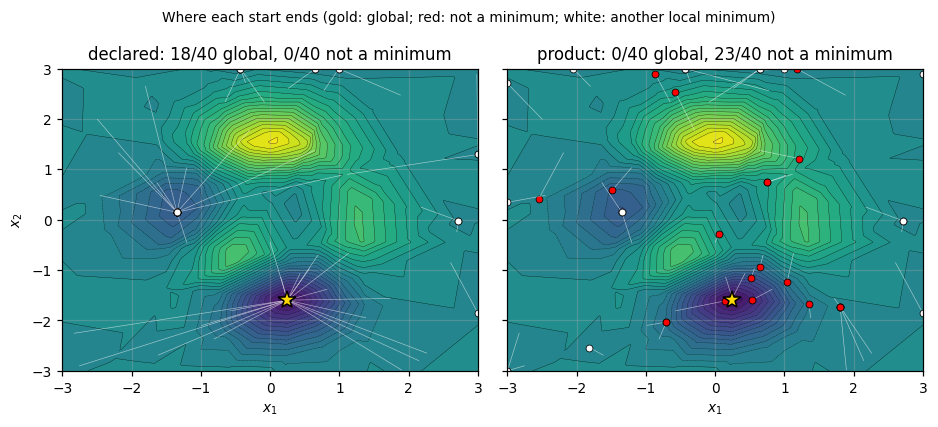

In [7]:
gx = np.linspace(-3, 3, 241)
GX, GY = np.meshgrid(gx, gx)
Z = net(W, b, np.c_[GX.ravel(), GY.ravel()]).reshape(GX.shape)
fig, axes = plt.subplots(1, 2, figsize=(8.6, 3.9), sharey=True)
for ax, name in zip(axes, runs):
    ax.contourf(GX, GY, Z, 30, cmap="viridis")
    ax.contour(GX, GY, Z, 30, colors="k", linewidths=0.2)
    for r in runs[name]:
        good = r["f"] <= F_STAR + tol
        stuck = r["drop"] > 1e-6
        ax.plot(*np.c_[r["x0"], r["x"]], color="w", lw=0.4, alpha=0.6)
        ax.plot(*r["x"], "o", ms=4.5, mfc="gold" if good else ("red" if stuck else "w"),
                mec="k", mew=0.5)
    ax.plot(*G["x"], "*", ms=12, mfc="gold", mec="k")
    n_glob = sum(r["f"] <= F_STAR + tol for r in runs[name])
    n_stuck = sum(r["drop"] > 1e-6 for r in runs[name])
    ax.set_title(f"{name}: {n_glob}/40 global, {n_stuck}/40 not a minimum")
    ax.set_xlabel("$x_1$")
axes[0].set_ylabel("$x_2$")
fig.suptitle("Where each start ends (gold: global; red: not a minimum; white: another local minimum)",
             fontsize=9)
fig.tight_layout()

The red points are the hand-written formulation's failure, and the dangerous
kind: `Solve_Succeeded`, a feasible point, and an objective that looks plausible,
on a kink the network still slopes down from. With the pairs declared, POUNCE's
complementarity driver does not stop there. Its first formulation is the Scholtes
relaxation \,(y - z) \le \tau$, which rounds every kink off while $\tau$ is
large, so the iterates can cross kinks before $\tau$ shrinks to the exact
problem. The stationarity certificate on every answer
(`info["complementarity"]["certificate"]`, here S on all 40) is computed on the
pairs themselves.

What remains are other local minima (white). That is the nature of a local
method, and of a surrogate fitted to a function with three wells. Multistart, or
the MILP, is the answer to that.

## 6. How the cost grows

The MILP is exact and the MPCC is not, so the question is what exactness costs.
Below, networks of growing width are trained on the same data (fewer epochs: the
fit is not the point). Each is minimized once by the MILP, capped at 120 s, and
from five starts by the declared pairs. The MILP's binaries are its unstable
units; their number, not the network's size, drives its branch and bound.

In [8]:
scale = []
for width in (8, 16, 32, 48, 64):
    Wk, bk = train([2, width, width, 1], X, Y, steps=3000, seed=width)
    Gk = milp_global(Wk, bk, LO, HI, time_limit=120)
    Pk = ReluProblem(Wk, bk, LO, HI)
    sols = [Pk.solve(x0) for x0 in STARTS[:5]]
    fbest = min(float(net(Wk, bk, s[0])[0]) for s in sols)
    scale.append(dict(width=width, units=2 * width, binaries=Gk["binaries"],
                      milp_wall=Gk["wall"], milp_proven=Gk["proven"], milp_f=Gk["f"],
                      mpcc_wall=float(np.median([s[2] for s in sols])), mpcc_best=fbest))
    s = scale[-1]
    print(f"width {width:3d}: {s['binaries']:3d} binaries, MILP "
          f"{'proven' if s['milp_proven'] else 'NOT proven'} in {s['milp_wall']:6.1f} s "
          f"(f = {'none' if s['milp_f'] is None else format(s['milp_f'], '+.4f')}); declared pairs median {s['mpcc_wall']:.2f} s per start, "
          f"best of 5 f = {s['mpcc_best']:+.4f}")

width   8:  16 binaries, MILP proven in    0.1 s (f = -6.3729); declared pairs median 0.04 s per start, best of 5 f = -6.3729


width  16:  32 binaries, MILP proven in    0.3 s (f = -6.6871); declared pairs median 0.12 s per start, best of 5 f = -6.6871


width  32:  64 binaries, MILP proven in   14.3 s (f = -6.6414); declared pairs median 0.26 s per start, best of 5 f = -6.6414


width  48:  96 binaries, MILP NOT proven in  120.0 s (f = -5.9407); declared pairs median 0.65 s per start, best of 5 f = -6.6797


width  64: 128 binaries, MILP NOT proven in  120.0 s (f = none); declared pairs median 1.22 s per start, best of 5 f = -6.6185


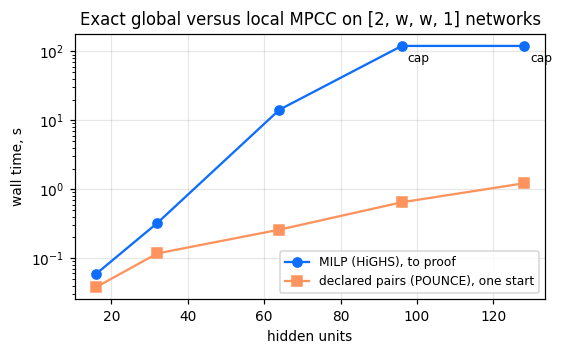

In [9]:
fig, ax = plt.subplots(figsize=(5.2, 3.3))
u = [s["units"] for s in scale]
ax.semilogy(u, [s["milp_wall"] for s in scale], "o-", label="MILP (HiGHS), to proof")
for s in scale:
    if not s["milp_proven"]:
        ax.annotate("cap", (s["units"], s["milp_wall"]), textcoords="offset points",
                    xytext=(4, -10), fontsize=8)
ax.semilogy(u, [s["mpcc_wall"] for s in scale], "s-", label="declared pairs (POUNCE), one start")
ax.set_xlabel("hidden units"); ax.set_ylabel("wall time, s")
ax.set_title("Exact global versus local MPCC on [2, w, w, 1] networks")
ax.legend(fontsize=8); fig.tight_layout()

## 7. The benchmark

`relu_nn` in the benchmark data root carries this comparison at larger scale and
against more solvers, under the `mpcc_compare` harness (`make -C benchmarks
mpcc-compare`). It has 42 problems on ten frozen networks. Six are surrogate
networks: `peaks` and Styblinski–Tang in 4 and 8 inputs, up to 3 layers and 128
units, each from 3 starts. Four are classifiers on scikit-learn's 8×8 digits, up
to $[64, 128, 128, 128, 10]$, posed as the *adversarial margin* problem:
minimize $\text{logit}_c - \text{logit}_t$ over an $\ell_\infty$ ball of radius
0.1 or 0.25 around a correctly classified image. A negative optimum means an
adversarial example exists inside the ball.

Truth is independent of every solver compared. Each problem has an MILP with
LP-tightened bounds, and for up to 8 inputs a branch and bound over the input
box with CROWN-style linear bounds. Both must agree wherever both prove
optimality, and a MILP certifies only when a second run with presolve off agrees:
HiGHS 1.13.1 returned a false Optimal on one problem there, which surfaced
because every compared solver went below it. Where neither does within 900 s, the problem is scored against the
best answer any arm reaches. See `relu_nn/README.md` there for the results.

## Takeaways

* A ReLU network is linear rows plus one complementarity pair per hidden unit.
  Declare the pairs (`complementarity=[(row, var), ...]`, or Pyomo `mpec`, or
  AMPL `complements`) instead of writing products.
* Written as products, a converged status is no evidence of a minimum. Check
  the network around the answer, as section 5 does.
* The MPCC is local and the MILP is global. Use the MILP while it proves
  quickly; past that, the MPCC still gives a stationary answer in about a
  second, and multistart covers the wells.